Student Performance Indicator


 Life cycle of Machine Learning Project:
1. Understand the Problem Statement
2. Data Collection
3. Data Checks
    1. check for null values
    2. check for duplicate values
    3. check data type
    4. check the number of unique values in each column
    5. check statistics of the dataset
    6. check various categories present in the different categorical column
4. Exploratory Data Analysis
5. Data Pre-Processing
6. Model Training
7. Choose best model

1. Problem Statement 
   1. This project understands how the student performance (test scores) is affected by other variables such as Gender,Ethnicity,Parental Level of Education,Lunch
   and Test Preparation Course.

2. Data Collection: 
    1. Data Source is : https://www.kaggle.com/datasets/spscientist/students-performance-in-exams
    2. Data is having 8 columns and 1000 Rows

3. Importing Required Packages and libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

Importing .CSV file of the dataset

In [2]:
df=pd.read_csv('data/stud.csv')

In [3]:
#show top 5 rows

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
##check the shape of data set
df.shape

(1000, 8)

3. Data Checks
    1. check for null values
    2. check for duplicate values
    3. check data type
    4. check the number of unique values in each column
    5. check statistics of the dataset
    6. check various categories present in the different categorical column

In [5]:
##check for missing values
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

There are no missing values in the data

In [6]:
##check for duplicate values
df.duplicated().sum()

np.int64(0)

There are no duplicate values in the dataset

In [7]:
##check for datatype
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


1. string datatype(gender,race/ethnicity, parental level of education,lunch,test preparation course) 
2. integer datatypes (math score,reading score, writing score)

In [8]:
##check for unique values in each column
df.nunique()

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

In [9]:
##check statistics of the dataset
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


1. Mean of all three features(math score, reading score, writing score) are very close to each other range from 66 to 69.
2. Standard Deviation is also very close of all features ranges from 14.6 to 15.16
3. Minimum Math score is 0.0 and reading score is 17.00(much higher) and writing score is 10.00 (higher)


Exploring Data

In [10]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [11]:
print("Categories in 'gender' variable:",format(df['gender'].unique()))

print("Categories in 'race/ethnicity' variable:",format(df['race/ethnicity'].unique()))

print("Categories in 'parental level of education' variable:",format(df['parental level of education'].unique()))

print("Categories in 'lunch' variable:",format(df['lunch'].unique()))

print("Categories in 'test preparation course' variable:",format(df['test preparation course'].unique()))



Categories in 'gender' variable: <StringArray>
['female', 'male']
Length: 2, dtype: str
Categories in 'race/ethnicity' variable: <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Categories in 'parental level of education' variable: <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable: <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test preparation course' variable: <StringArray>
['none', 'completed']
Length: 2, dtype: str


Extract the numerical and categorical features


In [12]:
##Extract Numerical features
Numerical_features=[features for features in df.columns if df[features].dtype=='int']
print(Numerical_features)
print("Number of Numerical Features are:",len(Numerical_features))\

##Extracting Categorical Features 
Categorical_features=[features for features in df.columns if df[features].dtype=='str']
print(Categorical_features)
print("Number of Categorical Features are:",len(Categorical_features))

['math score', 'reading score', 'writing score']
Number of Numerical Features are: 3
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']
Number of Categorical Features are: 5


Adding columns for Total Score and Calculate the Average Score
1. This Total Score will be our dependent feature for which on the given input we will predict Total Score
2. The Average Score can also be a dependent feature for which we can build a model to predict Average Score on the given input values

In [13]:
##adding one column total score and calculate the average
df['Total Score']=df['math score']+df['reading score']+df['writing score']
df['Average Score']=df['Total Score']/3

In [14]:
##looking for added columns
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Score,Average Score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [15]:
##Full marks achieved by students in all three subjects
reading_full=df[df['reading score']==100]['Average Score'].count()
writing_full=df[df['writing score']==100]['Average Score'].count()
math_full=df[df['math score']==100]['Average Score'].count()

print("Number of students with full marks in reading:",reading_full)
print("Number of students with full marks in writing:",writing_full)
print("Number of students with full marks in math:",math_full)

Number of students with full marks in reading: 17
Number of students with full marks in writing: 14
Number of students with full marks in math: 7


In [16]:
##Marks achieved less than 20 in each subject by students
reading_less_20=df[df['reading score']<=20]['Average Score'].count()
writing_less_20=df[df['writing score']<=20]['Average Score'].count()
math_less_20=df[df['math score']<=20]['Average Score'].count()

print("Number of students with less than 20 marks in reading:",reading_less_20)
print("Number of students with less than 20 marks in writing:",writing_less_20)
print("Number of students with less than 20 marks in math:",math_less_20)


Number of students with less than 20 marks in reading: 1
Number of students with less than 20 marks in writing: 3
Number of students with less than 20 marks in math: 4


Insights:
 1. From above values we get that the student is having worst performance in MATHS
 2. From above values we get that the student is having best performance in READING

4. Exploring Data (Visualization)
   1. Visualize average score distribution to make some conclusion.
      1. Histogram
      2. Kernel Distribution Function (KDE)

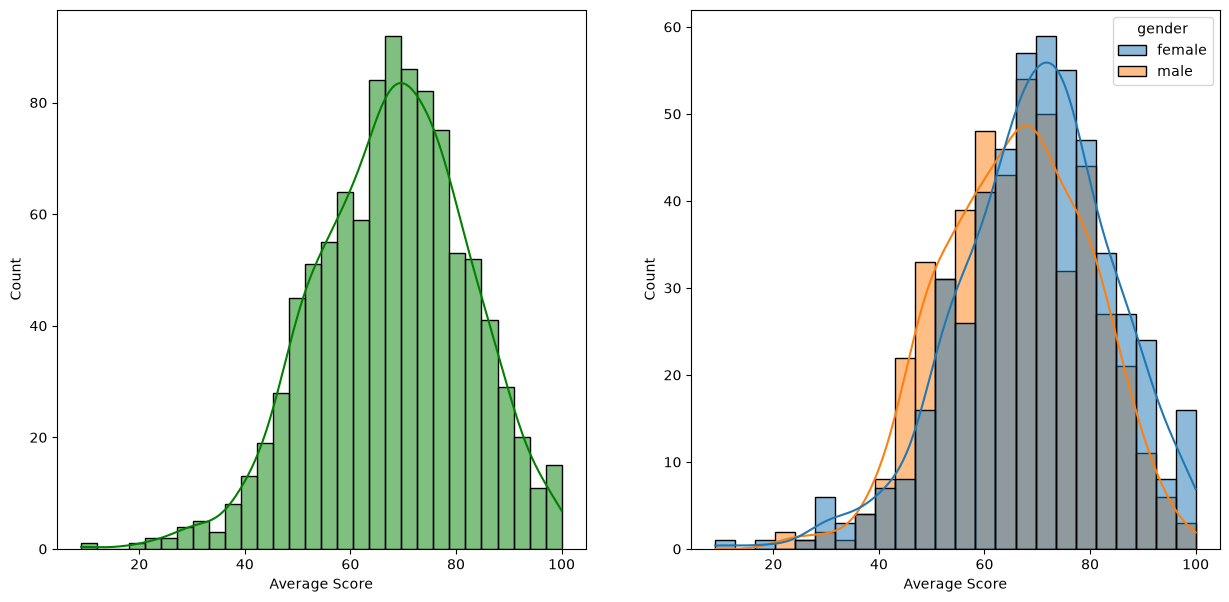

In [17]:
fig,axs=plt.subplots(1, 2, figsize=(15,7))
plt.subplot(121)
sns.histplot(x='Average Score',bins=30,kde=True,color='g',data=df)
plt.subplot(122)
sns.histplot(x='Average Score',kde=True,hue='gender',data=df)
plt.show()

Insights:

Female students are performing well as compare to male students with respect to average score

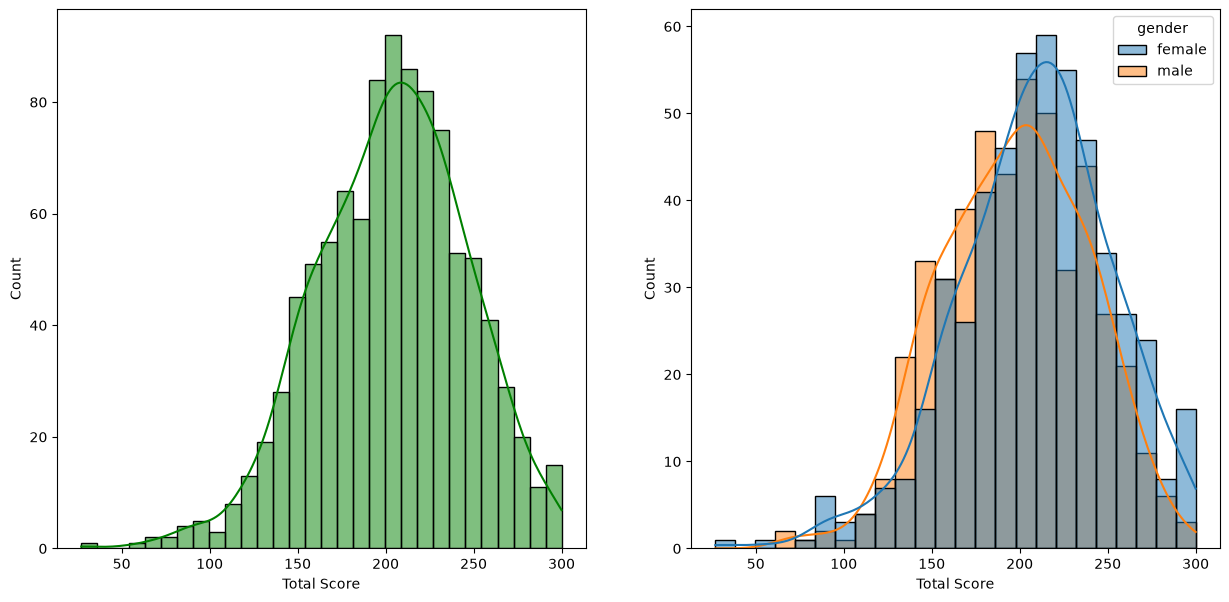

In [18]:
### Visualization of Total Score 
fig,axs=plt.subplots(1, 2, figsize=(15,7))
plt.subplot(121)
sns.histplot(data=df,x='Total Score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='Total Score',hue='gender',kde=True,color='b')
plt.show()

Insights:
1. With respect to total score female students are also performing well as compare to male students.

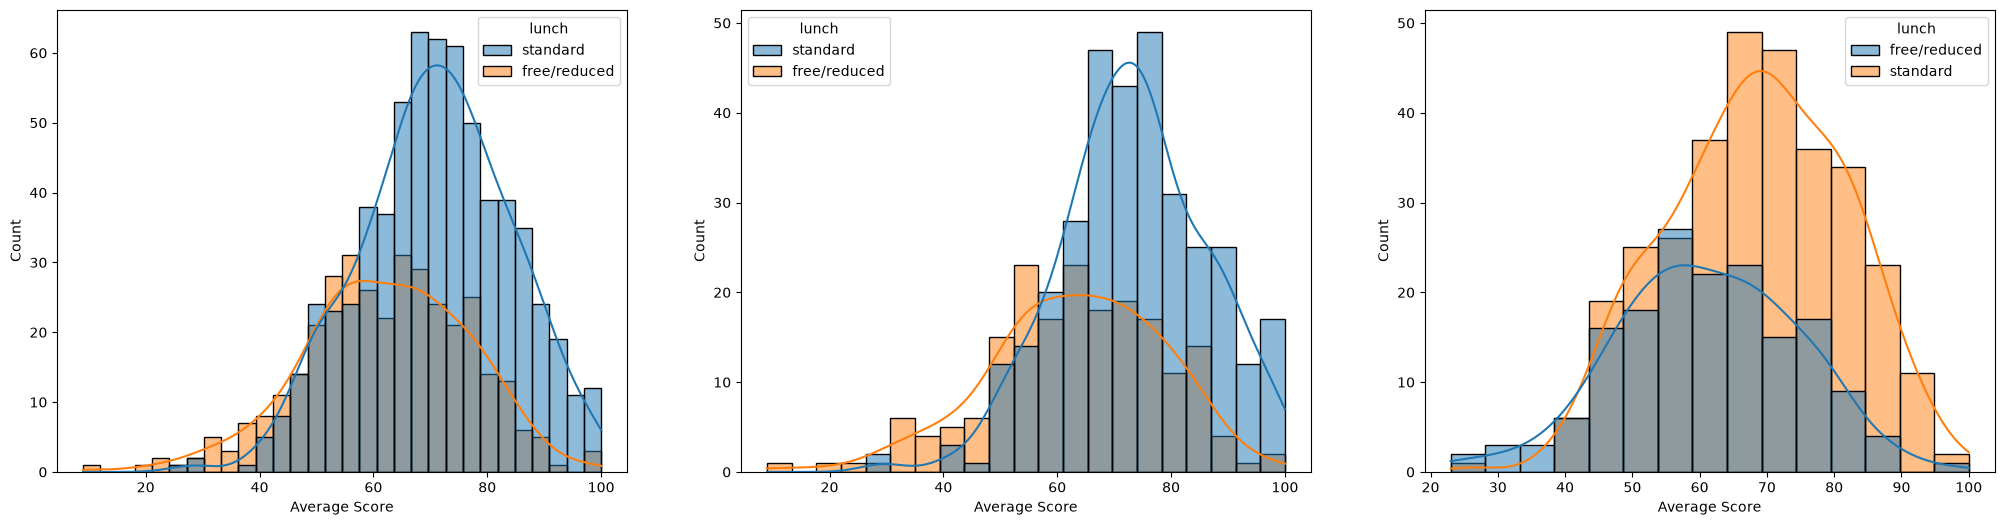

In [19]:
##Visualizing impact of lunch over average score on male and female and both 
fig,axs=plt.subplots(1,3,figsize=(25,6))
plt.subplot(131)
sns.histplot(x='Average Score',data=df,kde= True,bins=30,hue='lunch')
plt.subplot(132)
sns.histplot(x='Average Score',data=df[df['gender']=='female'],kde=True,hue='lunch')
plt.subplot(133)
sns.histplot(x='Average Score',data=df[df['gender']=='male'],kde=True,hue='lunch')
plt.show()

insight:
1. standard lunch helps to perform well in exams
2. and Standard lunch is also helps both male & female to perform well in exams


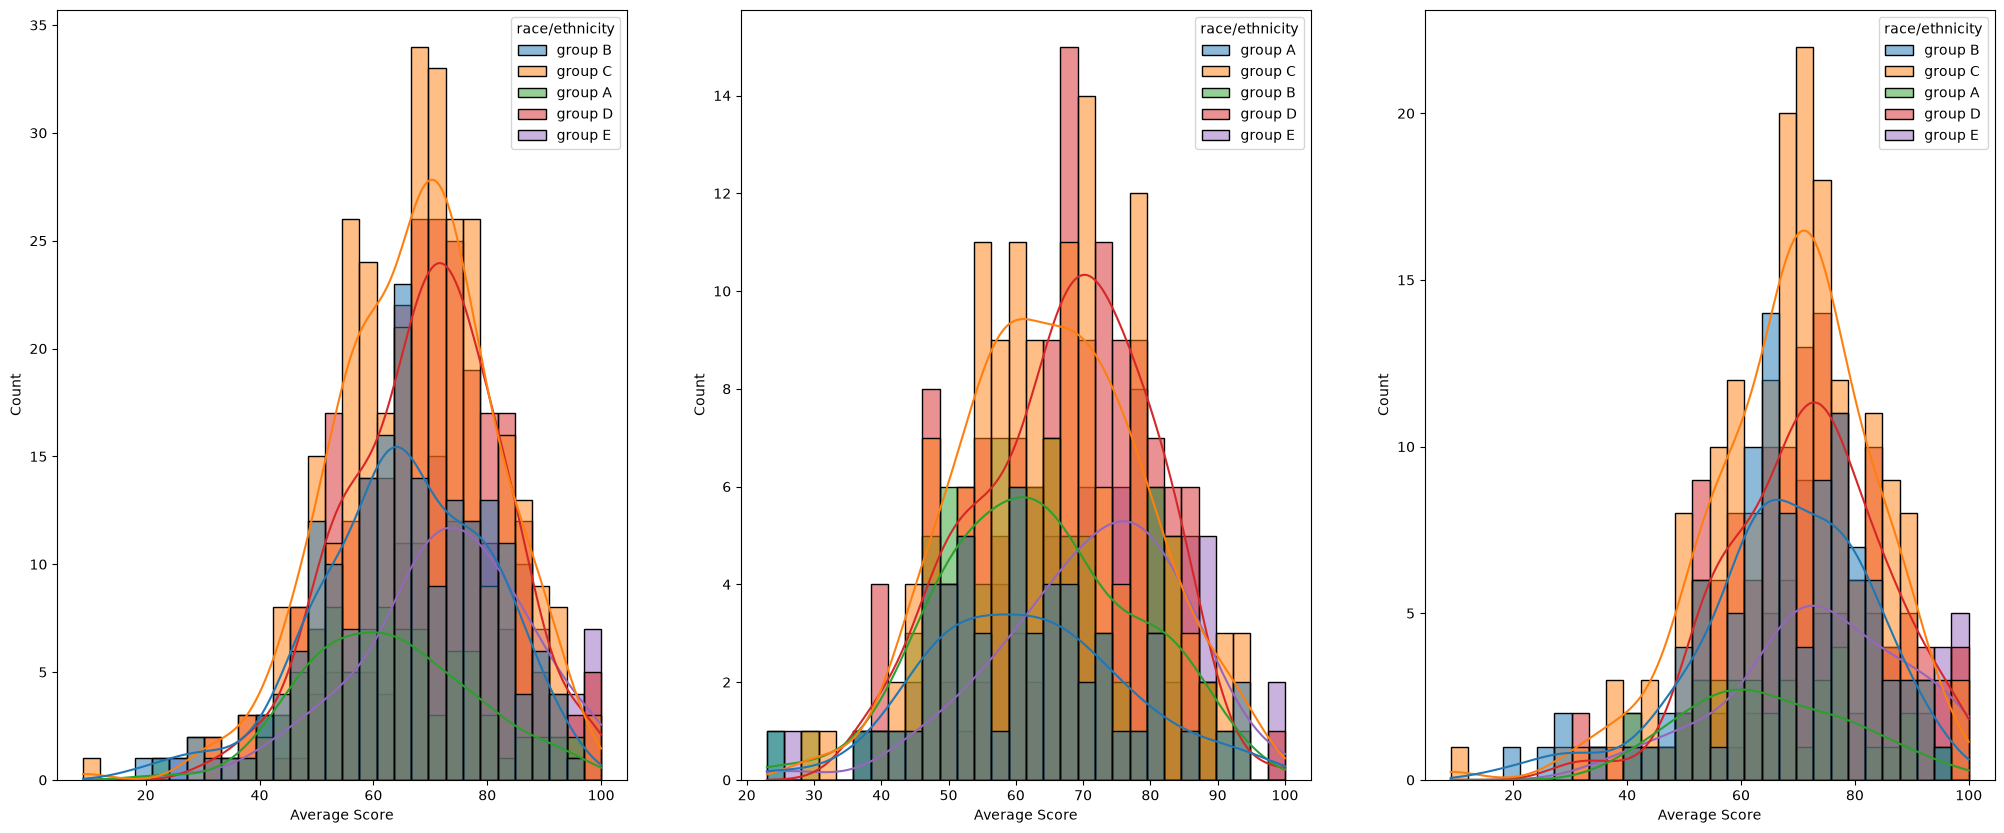

In [20]:
plt.subplots(1,3,figsize=(25,10))
plt.subplot(131)
sns.histplot(x='Average Score',bins=30,kde=True,data=df,hue='race/ethnicity')
plt.subplot(132)
sns.histplot(x='Average Score',bins=30,data=df[df['gender']=='male'],kde=True,hue='race/ethnicity')
plt.subplot(133)
sns.histplot(x='Average Score',bins=30,kde=True,data=df[df['gender']=='female'],hue='race/ethnicity')
plt.show()


insights:

good performance :

1. Combinely male and female students from group C ethncity have higher average score.
2. Male students from group D and Group C is performing well in exams.
3. Female students from Group C is performing well in exams.

poor performance:

1. students from group A and Group B tends to perform very poor in exams irrespective they are male or female.


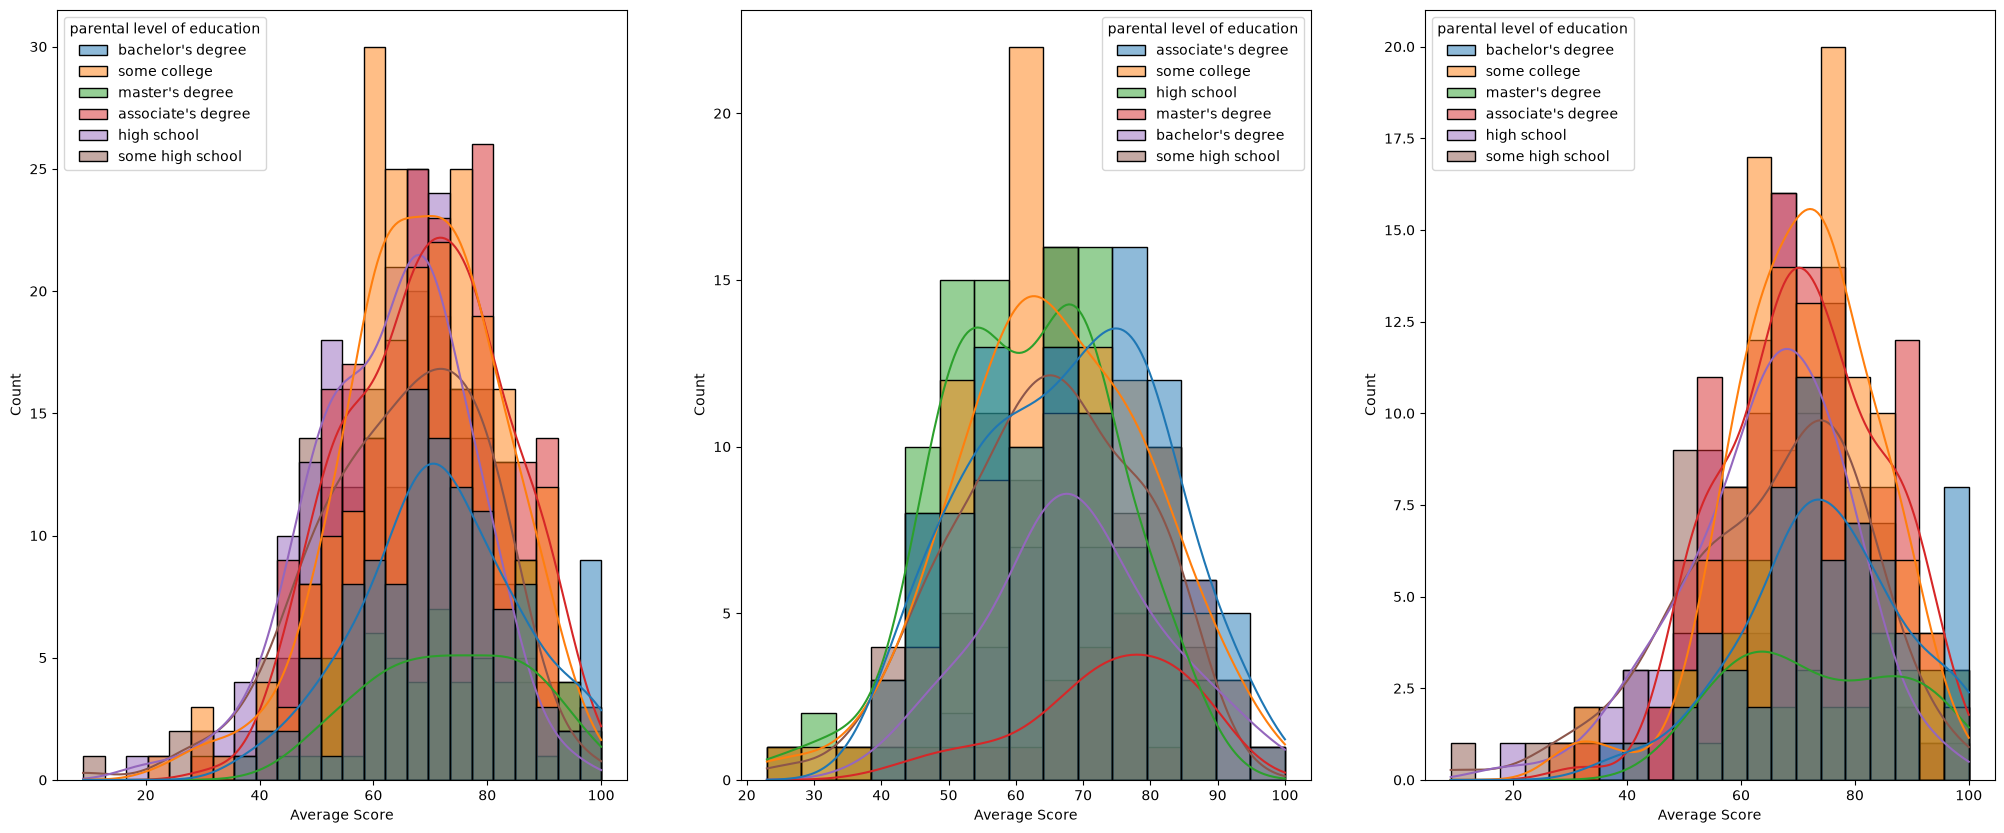

In [21]:
plt.subplots(1,3,figsize=(25,10))
plt.subplot(131)
ax=sns.histplot(x='Average Score',kde=True,data=df,hue='parental level of education')
plt.subplot(132)
ax=sns.histplot(x='Average Score',data=df[df['gender']=='male'],kde=True,hue='parental level of education')
plt.subplot(133)
ax=sns.histplot(x='Average Score',kde=True,data=df[df['gender']=='female'],hue='parental level of education')
plt.show()


insights:
1. in general parents education does not help students to perform well in exams
2. in 2nd plot that parent's who is having associates degree or masters degree their male child more tends to perform well in exams.
3. 3rd plot we can see there is no effect of parent's education on female students.

In [22]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Score,Average Score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


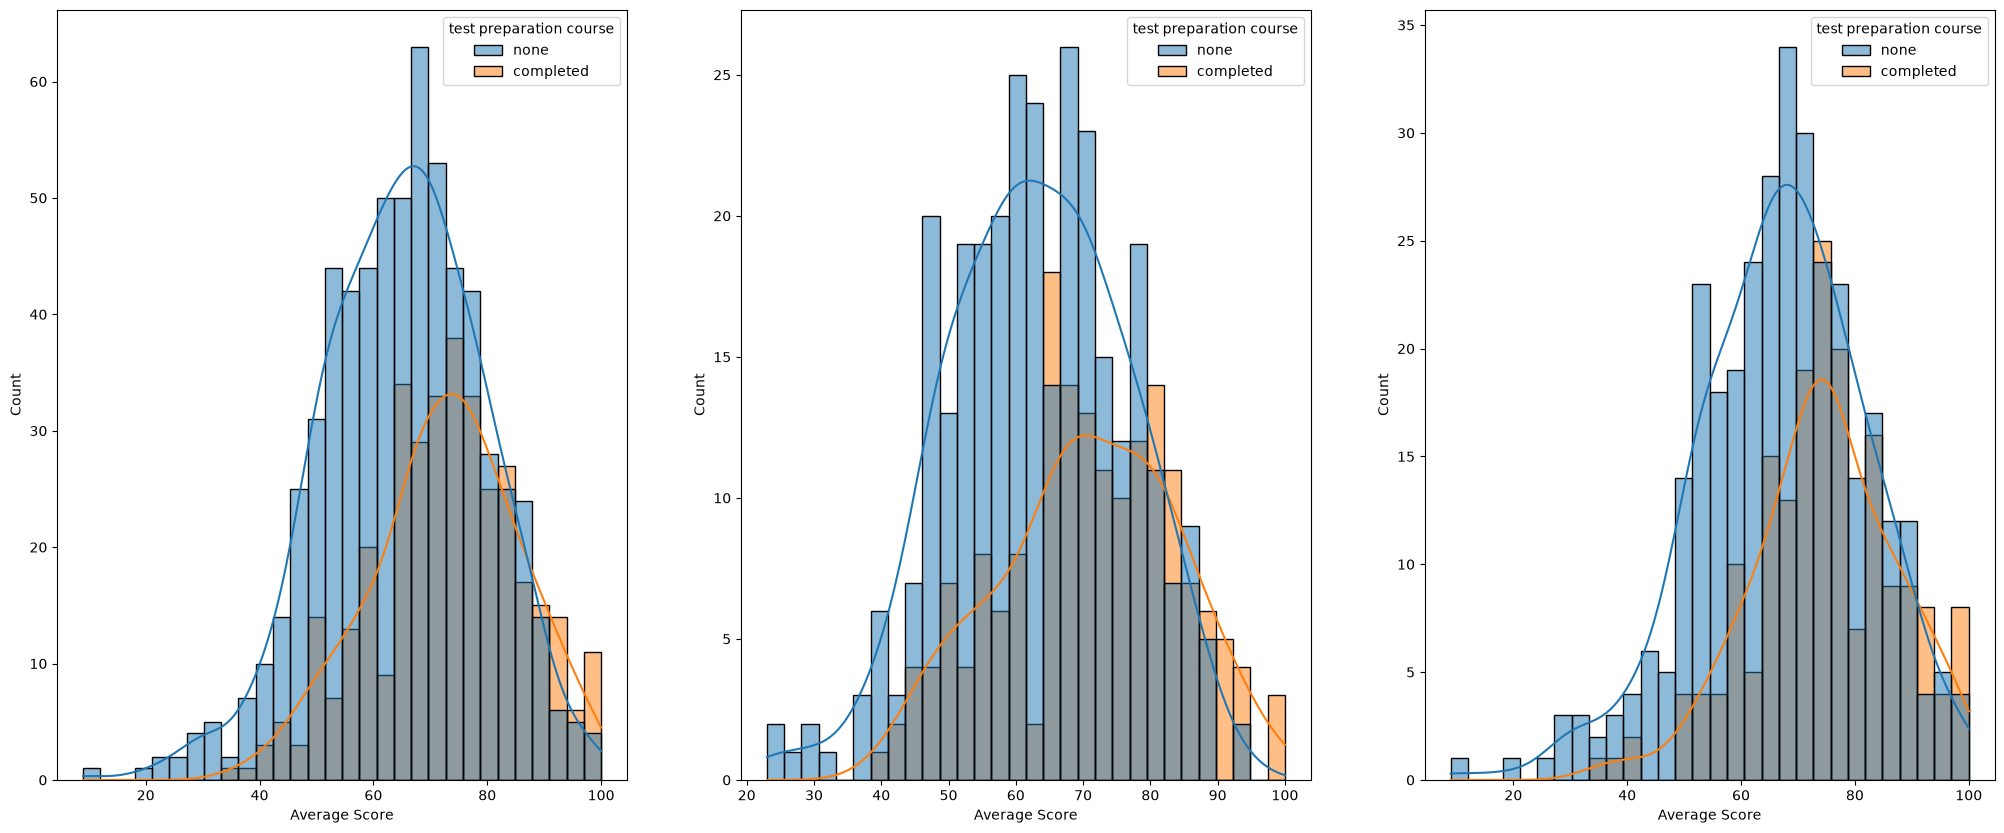

In [23]:
plt.subplots(1,3,figsize=(25,10))
plt.subplot(131)
sns.histplot(x='Average Score',bins=30,kde=True,data=df,hue='test preparation course')
plt.subplot(132)
sns.histplot(x='Average Score',bins=30,data=df[df['gender']=='male'],kde=True,hue='test preparation course')
plt.subplot(133)
sns.histplot(x='Average Score',bins=30,kde=True,data=df[df['gender']=='female'],hue='test preparation course')
plt.show()

Insights:
1. in general the students (both male and female who have not completed the test preparation) performing well in the exams.


Visualization of the maximum scores of students in all three subjects

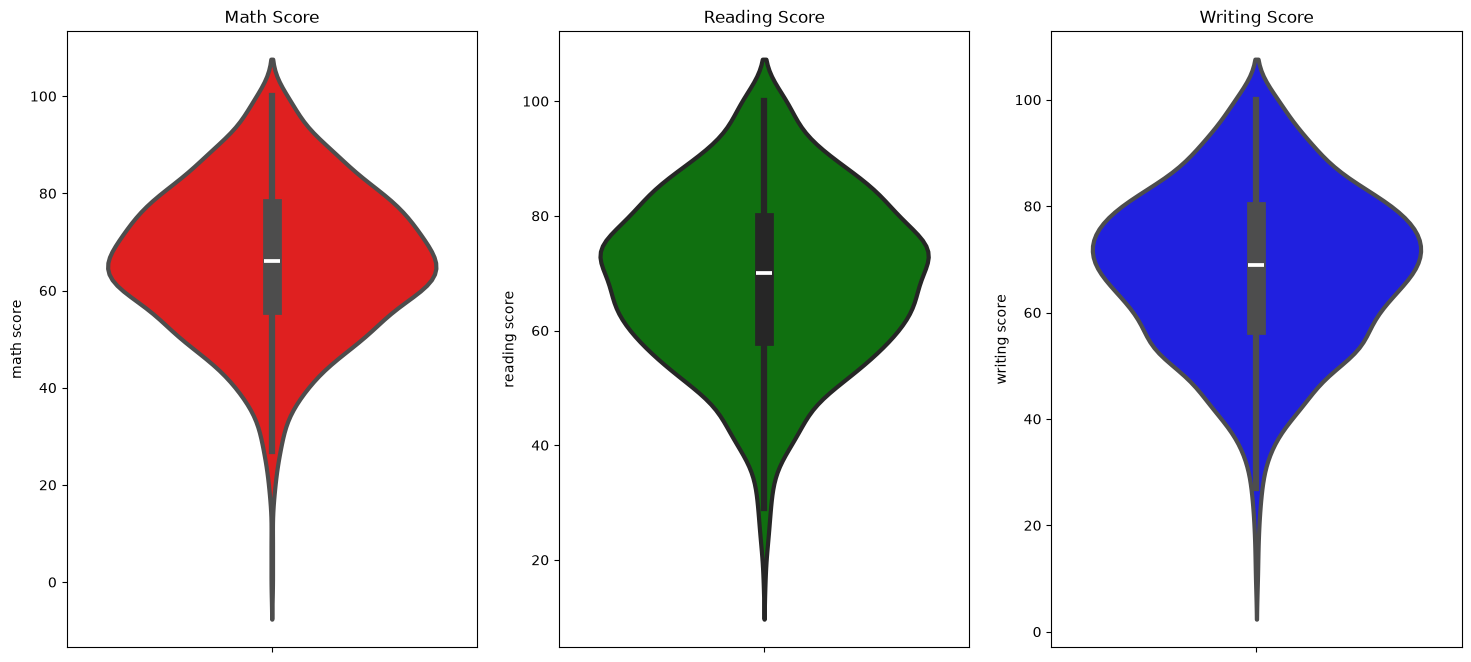

In [24]:
plt.figure(figsize=(18,8))

plt.subplot(1,3,1)
plt.title("Math Score")
sns.violinplot(y='math score',data=df,color='red',linewidth=3)

plt.subplot(1,3,2)
plt.title("Reading Score")
sns.violinplot(y='reading score',data=df,color='green',linewidth=3)

plt.subplot(1,3,3)
plt.title("Writing Score")
sns.violinplot(y='writing score',data=df,color='blue',linewidth=3)
plt.show()

Insights:
   1. From the above observation in all three plots (math, reading, writing) students scores between 60 - 80. 

Multivariate Analysis using PiePlot

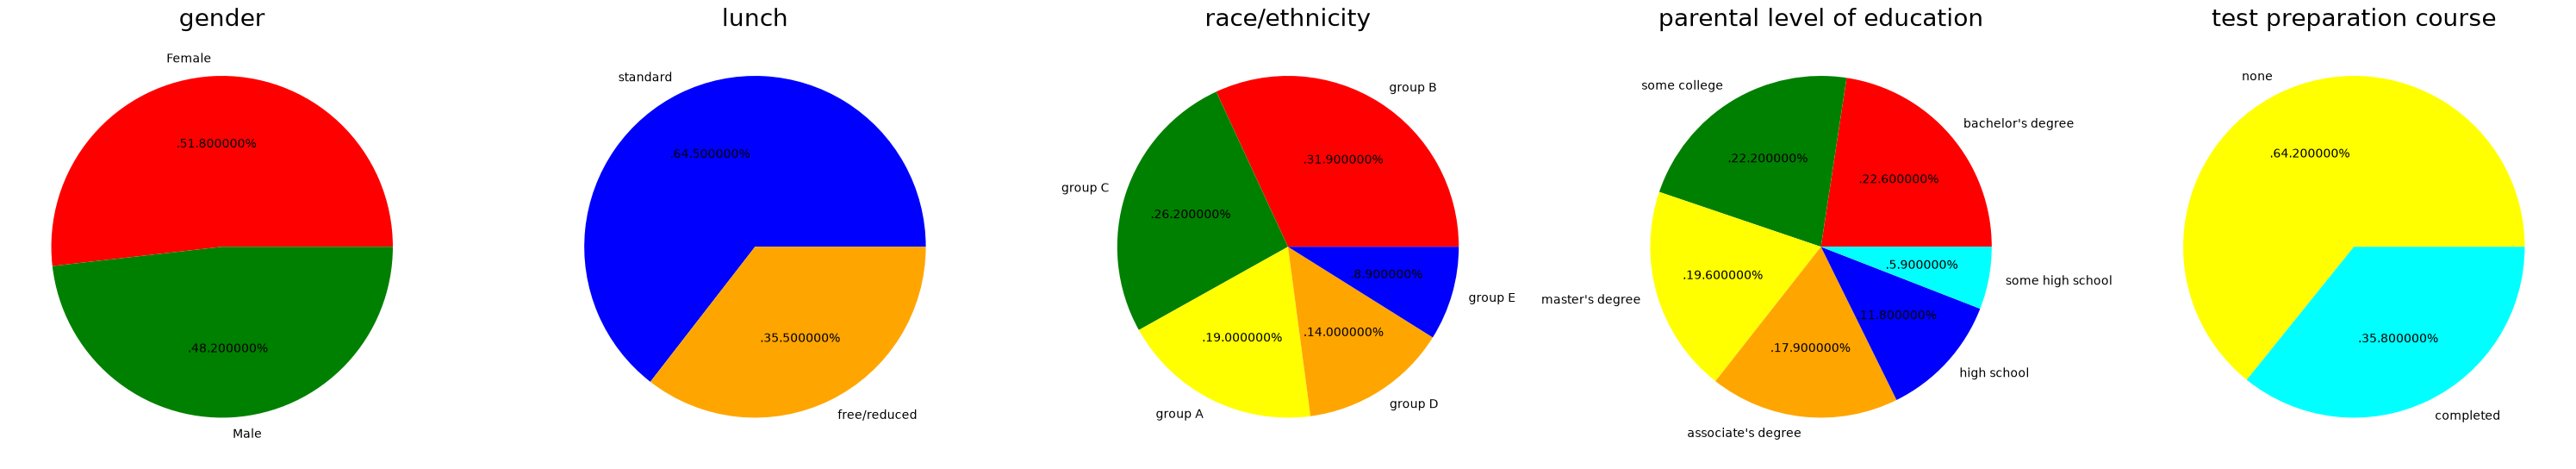

In [25]:
plt.figure(figsize=(30,20))

##Gender
plt.subplot(1,5,1)
size=df['gender'].value_counts()
label='Female','Male'
color=['red','green']

plt.pie(size,colors=color,labels=label,autopct='.%2f%%')
plt.title('gender',fontsize= 20)
plt.axis('off')

##Lunch
plt.subplot(1,5,2)
size=df['lunch'].value_counts()
label='standard', 'free/reduced'
color=['blue','orange']

plt.pie(size,colors=color,labels=label,autopct='.%2f%%')
plt.title('lunch',fontsize= 20)
plt.axis('off')

##race/ethnicity
plt.subplot(1,5,3)
size=df['race/ethnicity'].value_counts()
label=['group B', 'group C', 'group A', 'group D', 'group E']
color=['red','green','yellow','orange','blue']

plt.pie(size,colors=color,labels=label,autopct='.%2f%%')
plt.title('race/ethnicity',fontsize= 20)
plt.axis('off')

##parental level of education
plt.subplot(1,5,4)
size=df['parental level of education'].value_counts()
label="bachelor's degree",'some college',"master's degree","associate's degree",'high school','some high school'
color=['red','green','yellow','orange','blue','cyan']

plt.pie(size,colors=color,labels=label,autopct='.%2f%%')
plt.title('parental level of education',fontsize=20)
plt.axis('off')

##test preparation course
plt.subplot(1,5,5)
size=df['test preparation course'].value_counts()
label=['none','completed']
color=['yellow','cyan']

plt.pie(size,colors=color,labels=label,autopct='.%2f%%')
plt.title('test preparation course',fontsize=20)
plt.axis('off')


plt.grid()
plt.tight_layout()
plt.show()

Insights:
1. number of male and female student's percentage are nearly equal.
2. Students with Standard Lunch is large in proportion.
3. in race/ethnicity Group B Students are greatest.
4. In Parental level of education some college and bachelor's degree proportions are qual.
5. Majority of the students who did not enrolled for test preparation course. 

Feature wise Visualization

1. Gender column
   1. How gender is distributed? (Univariate analysis)
   2. is gender is having any impact on student performance? (Bivariate analysis)
   


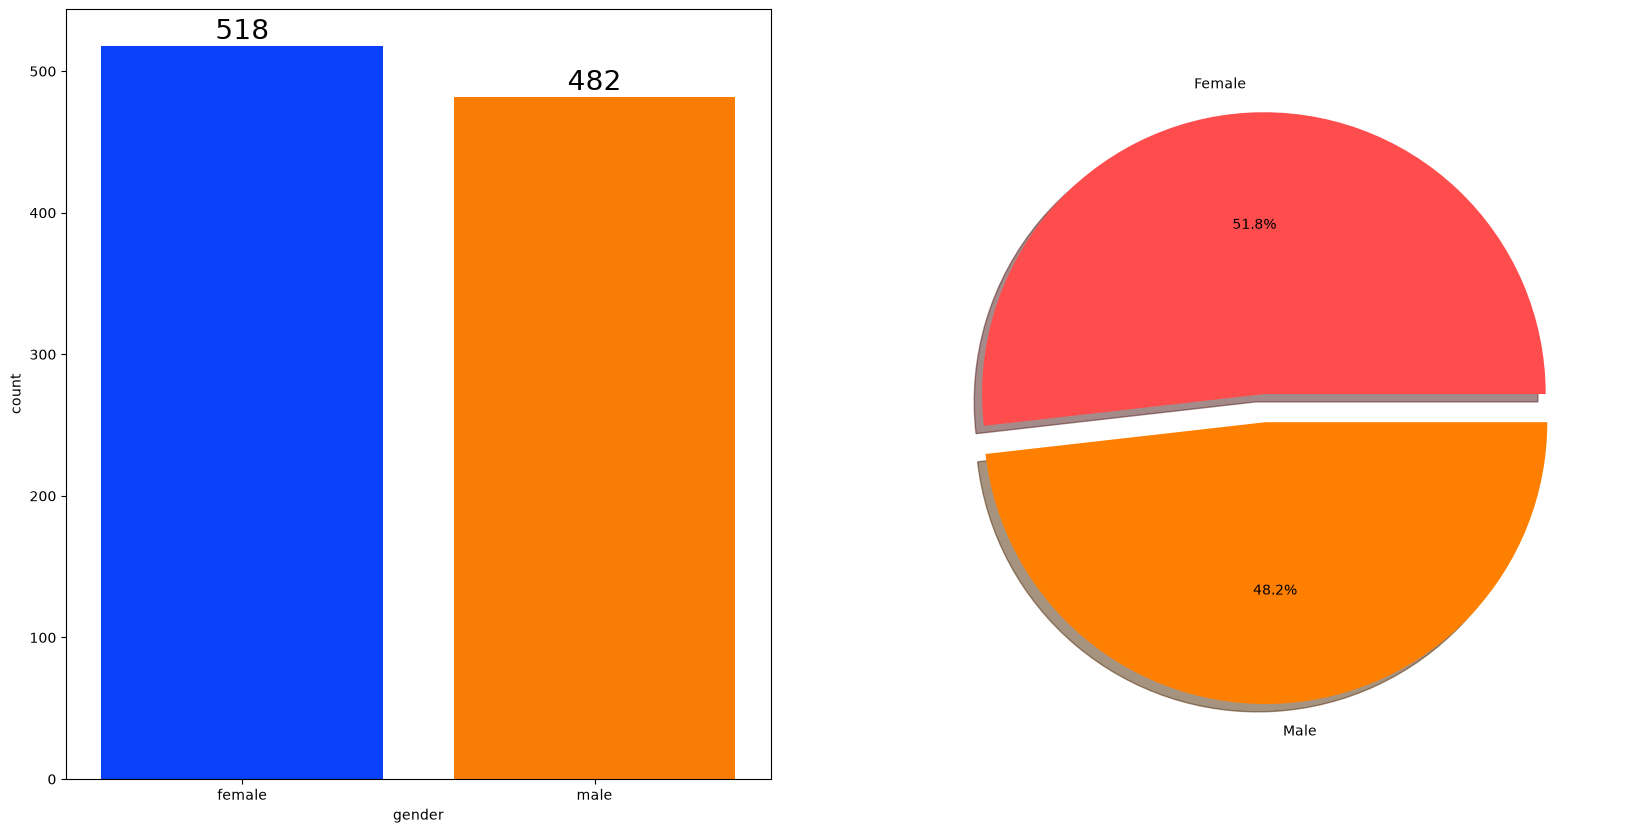

In [26]:
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(x=df['gender'],data=df,palette ='bright',ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    
plt.pie(x=df['gender'].value_counts(),labels=['Female','Male'],explode=[0,0.1],autopct='%1.1f%%',shadow=True,colors=['#ff4d4d','#ff8000'])
plt.show() 

Insight:
1. Gender is having balanced data with male students are 518 (51.8%) and female students are 482(48.2%).

In [27]:
gender_group = df.groupby('gender').mean(numeric_only=True)
gender_group


,math score,reading score,writing score,Total Score,Average Score
gender,,,,,
female,63.633205,72.608108,72.467181,208.708494,69.569498
male,68.728216,65.473029,63.311203,197.512448,65.837483


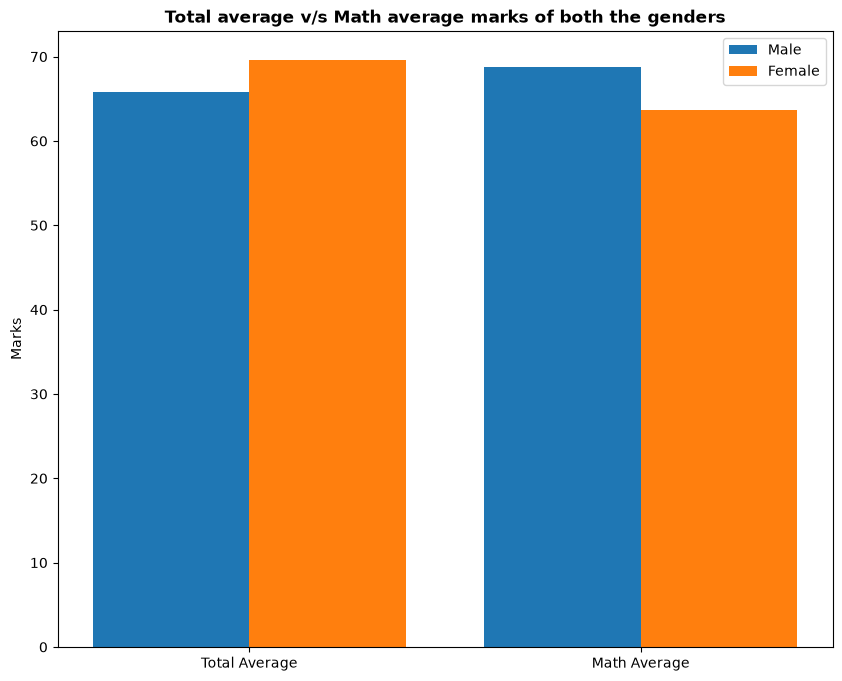

In [28]:
plt.figure(figsize=(10, 8))

X = ['Total Average','Math Average']


female_scores = [gender_group.loc['female','Average Score'], gender_group.loc['female','math score']]
male_scores = [gender_group.loc['male','Average Score'], gender_group.loc['male','math score']]

X_axis = np.arange(len(X))
  
plt.bar(X_axis - 0.2, male_scores, 0.4, label = 'Male')
plt.bar(X_axis + 0.2, female_scores, 0.4, label = 'Female')
  
plt.xticks(X_axis, X)
plt.ylabel("Marks")
plt.title("Total average v/s Math average marks of both the genders", fontweight='bold')
plt.legend()
plt.show() 

 Race/Ethnicity
  1. How race/ethnicity is group wise distributed?(univariate analysis)
  2. is race/ethnicity is having any impact on student's performance? (bivariate analysis)

Univariate Analysis(Race/Ethnicity) Distribution

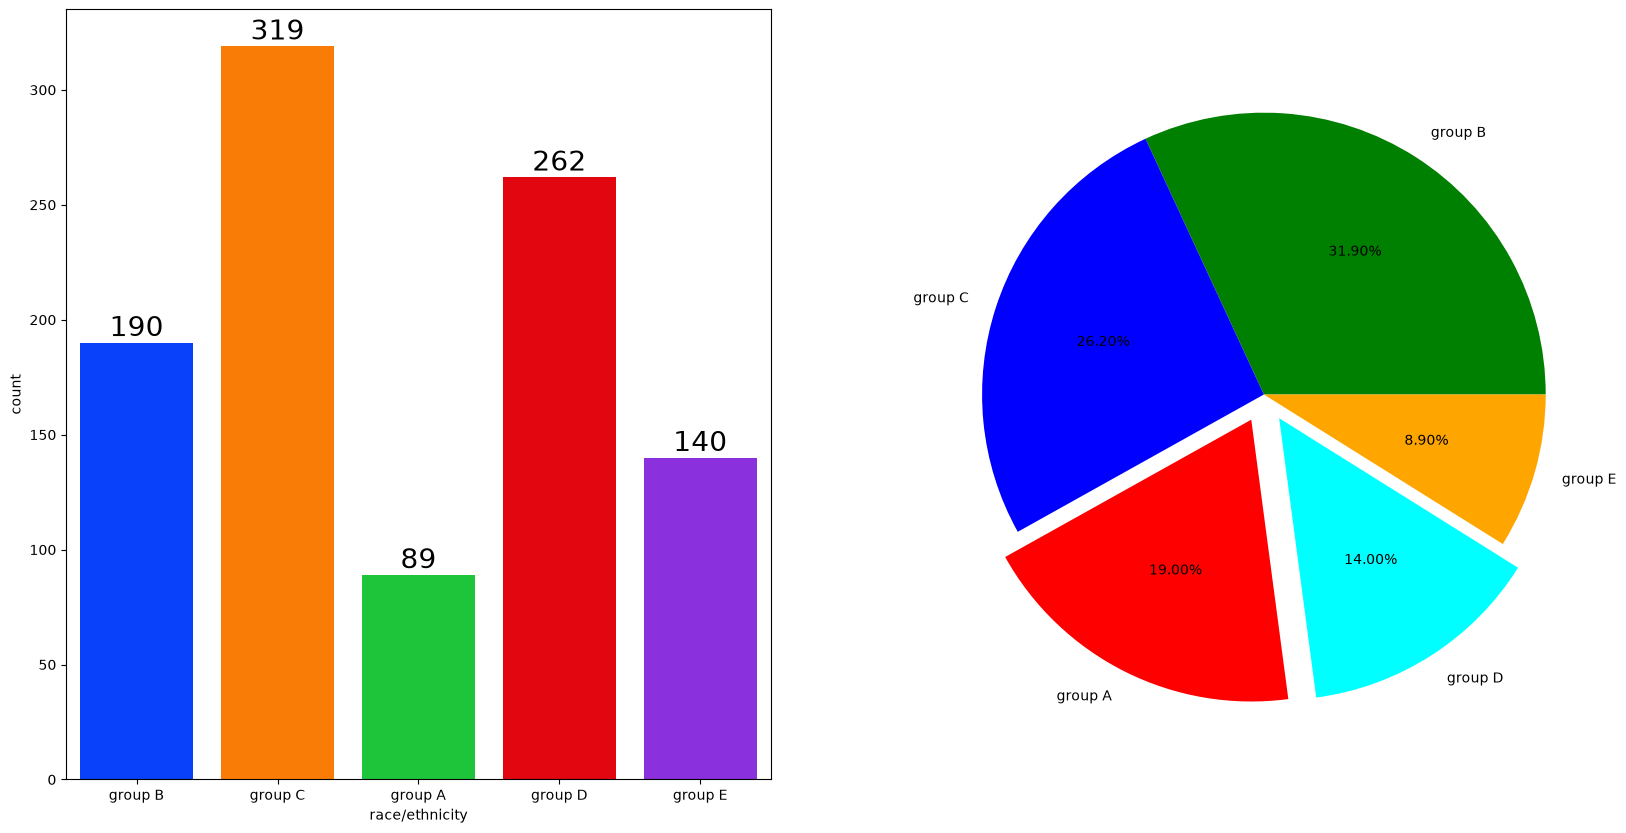

In [29]:
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(x=df['race/ethnicity'],palette='bright',data=df,ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)


distribution=df['race/ethnicity'].value_counts()
label=['group B', 'group C', 'group A', 'group D', 'group E']
color=['green','blue','red','cyan','orange']
explode=[0,0,0.1,0.1,0]
plt.pie(distribution,labels=label,colors=color,autopct='%.2f%%',explode=explode)
plt.show()

Insight:
1. maximum student belongs to Group C and Group D
2. minimum students belongs to Group A

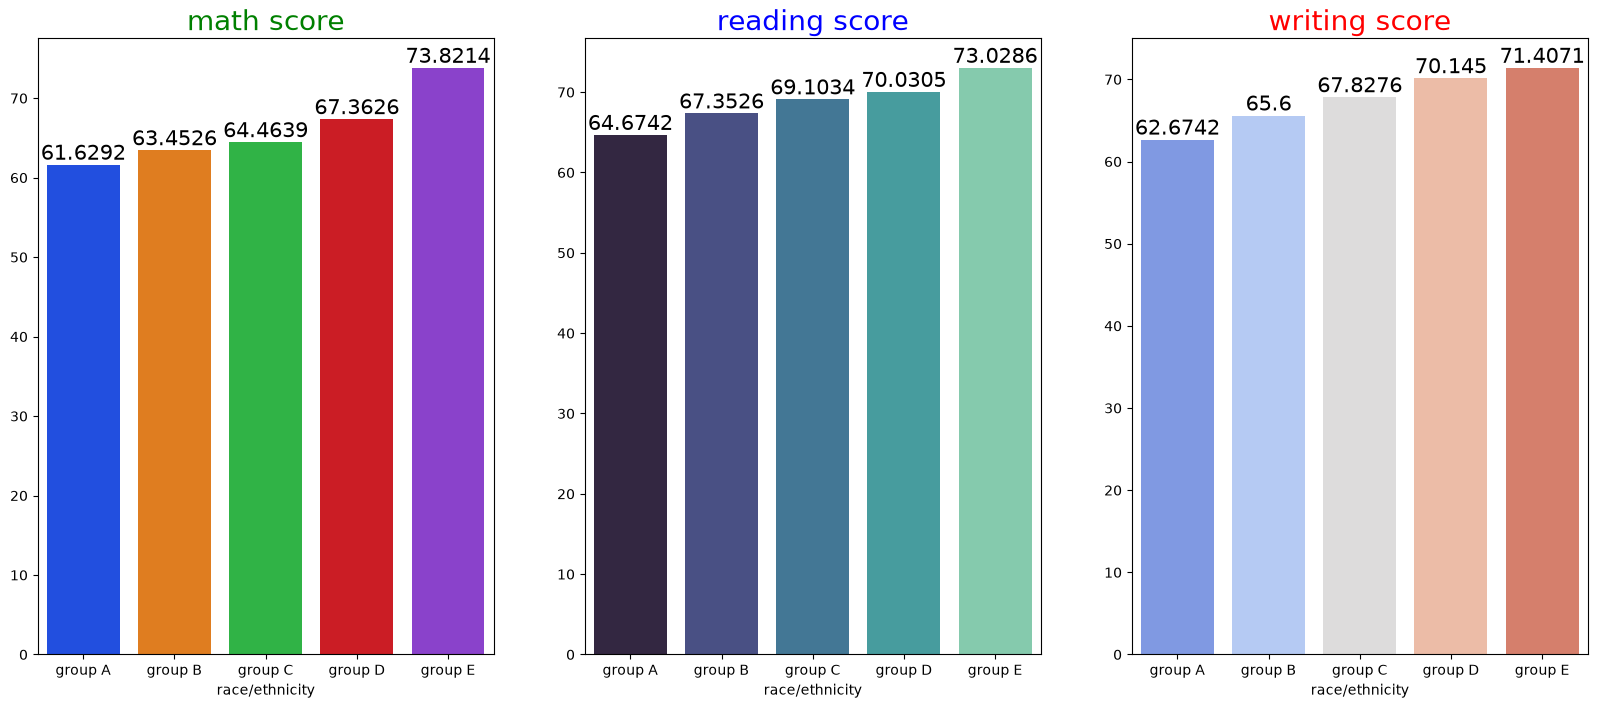

In [30]:
##Bivariate Analysis (race/ethnicity)
group_data2=df.groupby('race/ethnicity')
f,ax=plt.subplots(1,3,figsize=(20,8))
sns.barplot(x=group_data2['math score'].mean().index,y=group_data2['math score'].mean().values,palette='bright',ax=ax[0])
ax[0].set_title('math score',color='green',size=20)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=15)

sns.barplot(x=group_data2['reading score'].mean().index,y=group_data2['reading score'].mean().values,palette='mako',ax=ax[1])
ax[1].set_title('reading score',color='blue',size=20)
for container in ax[1].containers:
    ax[1].bar_label(container,color='black',size=15)

sns.barplot(x=group_data2['writing score'].mean().index,y=group_data2['writing score'].mean().values,palette='coolwarm',ax=ax[2])
ax[2].set_title('writing score',color='red',size=20)
for container in ax[2].containers:
    ax[2].bar_label(container,color='black',size=15)



Insights:
 1. Students from Group E is performing well in all three subjects. 
 2. Students from Group A is achieved lowest marks.
 

PARENTAL LEVEL OF EDUCATION
1. Univariate analysis (what is the educational background of student's parents?)
2. Bivariate analysis (is parents education has any impact on student's performance?)

findfont: Failed to find font weight 30 for DejaVu Sans, now using 400.


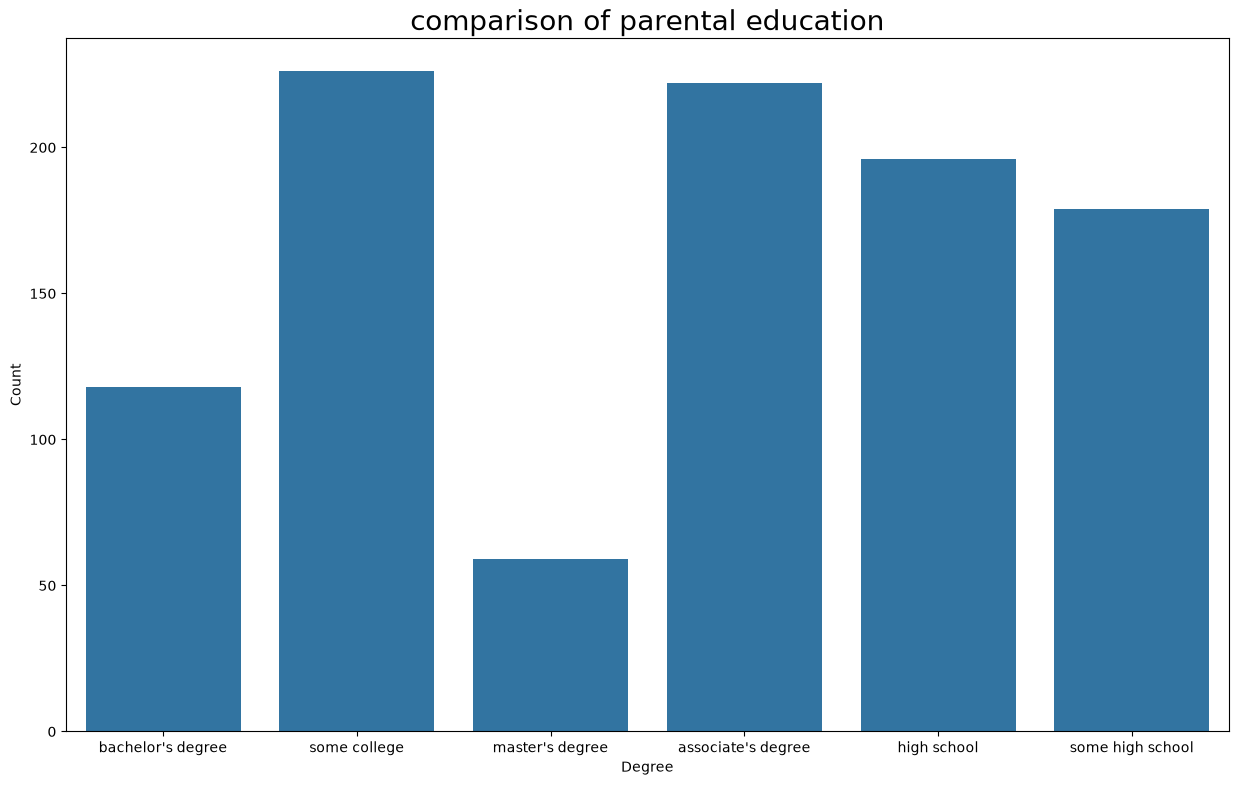

In [31]:
##Univariate analysis (what is the educational background of student's parents?)
plt.figure(figsize=(15,9))
sns.countplot(x=df['parental level of education'])
plt.title("comparison of parental education",fontweight=30,fontsize=20)
plt.xlabel("Degree")
plt.ylabel("Count")
plt.show()

insight:
1. Majority of the Parents are having Some College education. 

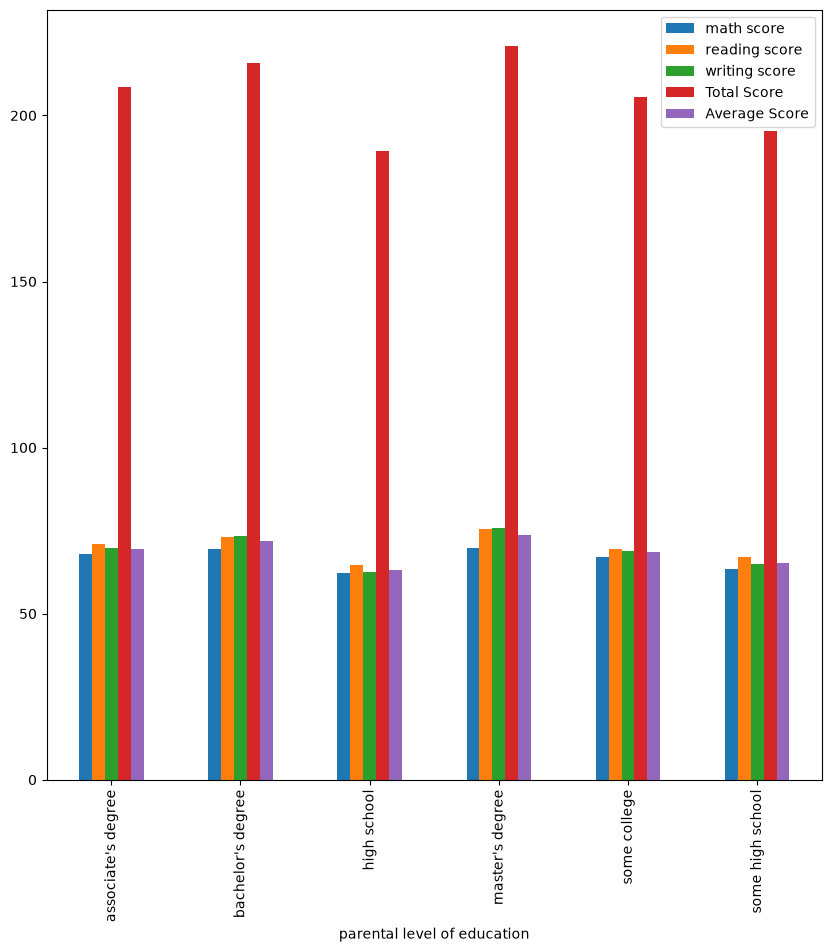

In [32]:
#Bivariate analysis (is parents education has any impact on student's performance?)
df.groupby('parental level of education').mean(numeric_only=True).plot(kind='bar',figsize=(10,10))
plt.show()

Insight:
1. Students whose parents is hanving bachelor's degree or master's degree is performing well.


# Lunch Columns 
  1. Univariate Analysis(Which type of lunch is most common among students?)
  2. Bivariate analysis (what is the effect of lunch type on test results?)

Text(0, 0.5, 'count')

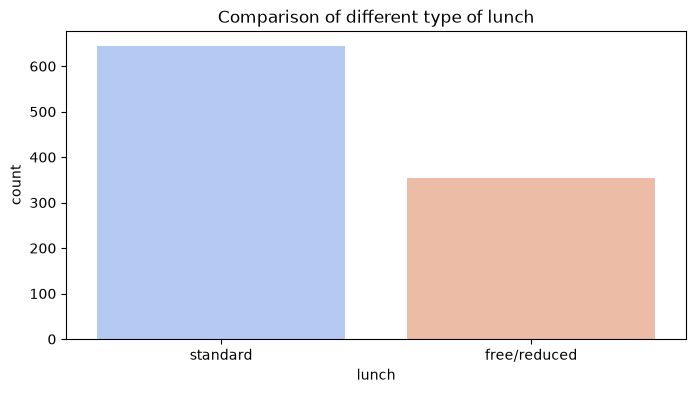

In [33]:
#Univariate Analysis(Which type of lunch is most common among students?)
plt.figure(figsize=(8,4))
sns.countplot(x=df['lunch'],palette='coolwarm')
plt.title("Comparison of different type of lunch")
plt.xlabel("lunch")
plt.ylabel("count")


Insights:
 1. Majority of the students are having standard lunch 

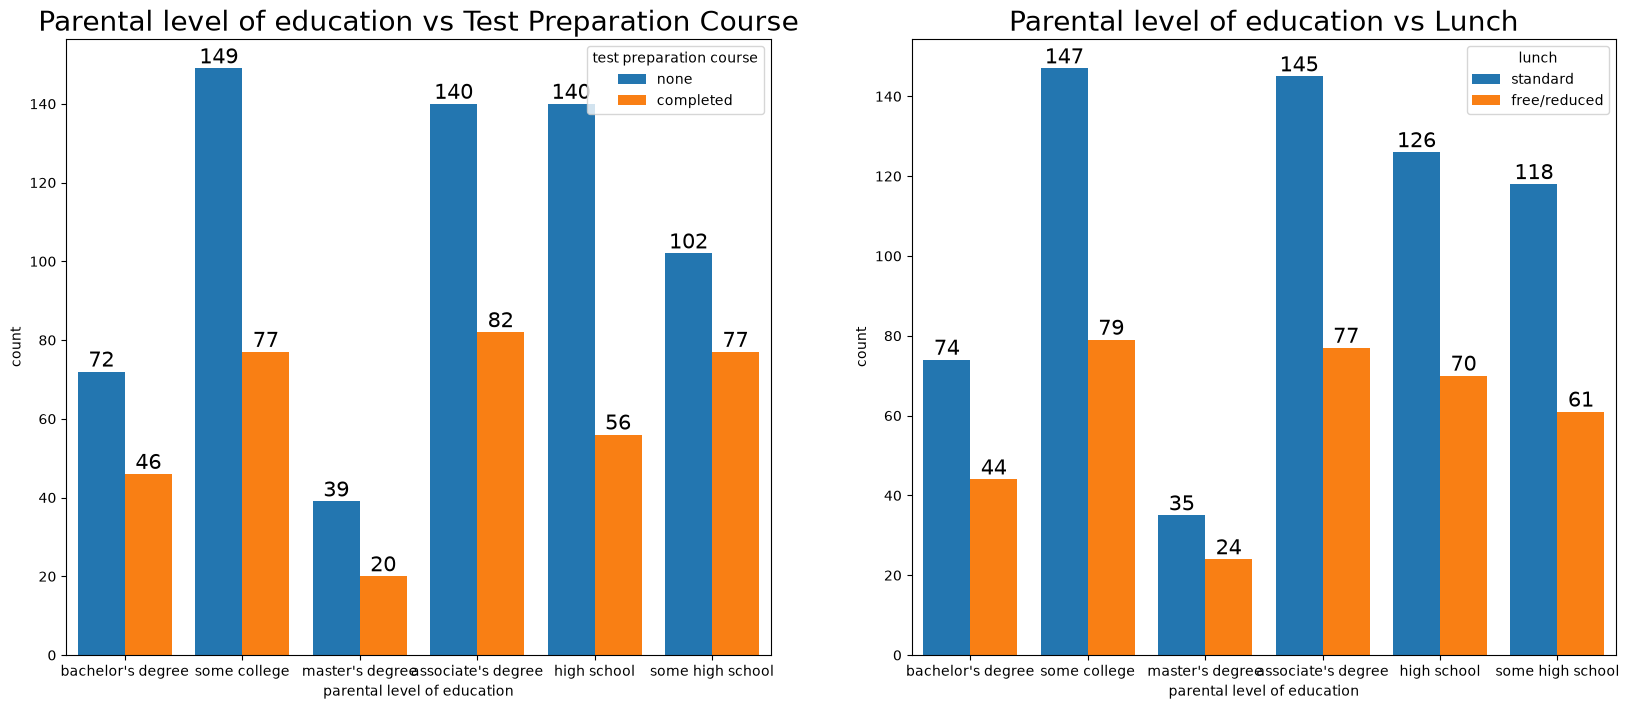

In [34]:
#Bivariate analysis (Is lunch type intake has any impact on student's performance)
f,ax=plt.subplots(1,2,figsize=(20,8))
sns.countplot(x=df['parental level of education'],data=df,hue='test preparation course',saturation=0.95,ax=ax[0])
ax[0].set_title("Parental level of education vs Test Preparation Course",color='black',size=20)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=15)

sns.countplot(x=df['parental level of education'],data=df,hue='lunch',saturation=0.95,ax=ax[1])
ax[1].set_title("Parental level of education vs Lunch",color='black',size=20)
for container in ax[1].containers:
    ax[1].bar_label(container,color='black',size=15)



Insights:
1. Students who got standard lunch tends to perform well as compare to the students who got free/reduced lunch.


Test Preparation Course Column
1. Bivariate Analysis(Is Test preparation course has any impact on student's performance?)


<Axes: xlabel='lunch', ylabel='writing score'>

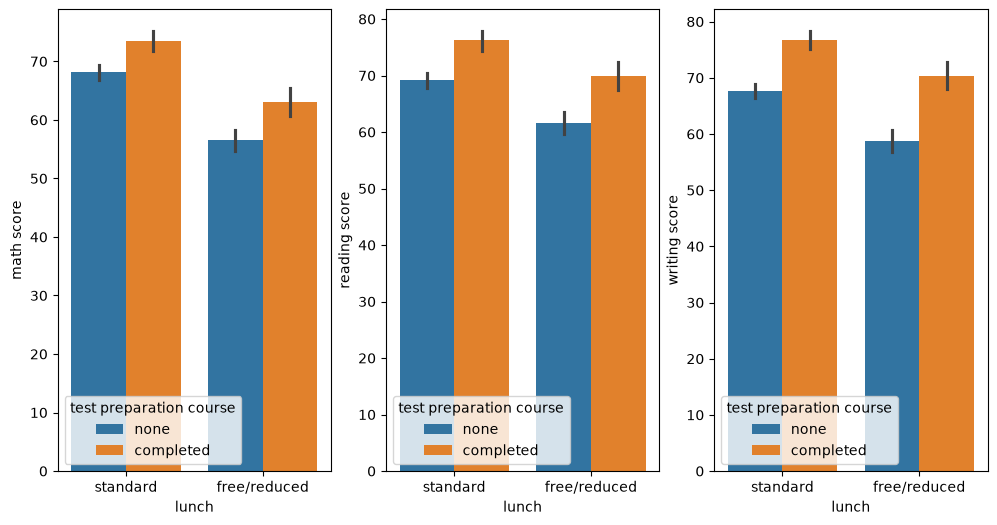

In [35]:
plt.subplots(1,3,figsize=(12,6))
plt.subplot(131)
sns.barplot(x=df['lunch'],y=df['math score'],hue=df['test preparation course'])
plt.subplot(132)
sns.barplot(x=df['lunch'],y=df['reading score'],hue=df['test preparation course'])
plt.subplot(133)
sns.barplot(x=df['lunch'],y=df['writing score'],hue=df['test preparation course'])



Insights:
1. Students who are having Standard lunch and completed the test preparation course are achieved the highest marks in all three subjects.

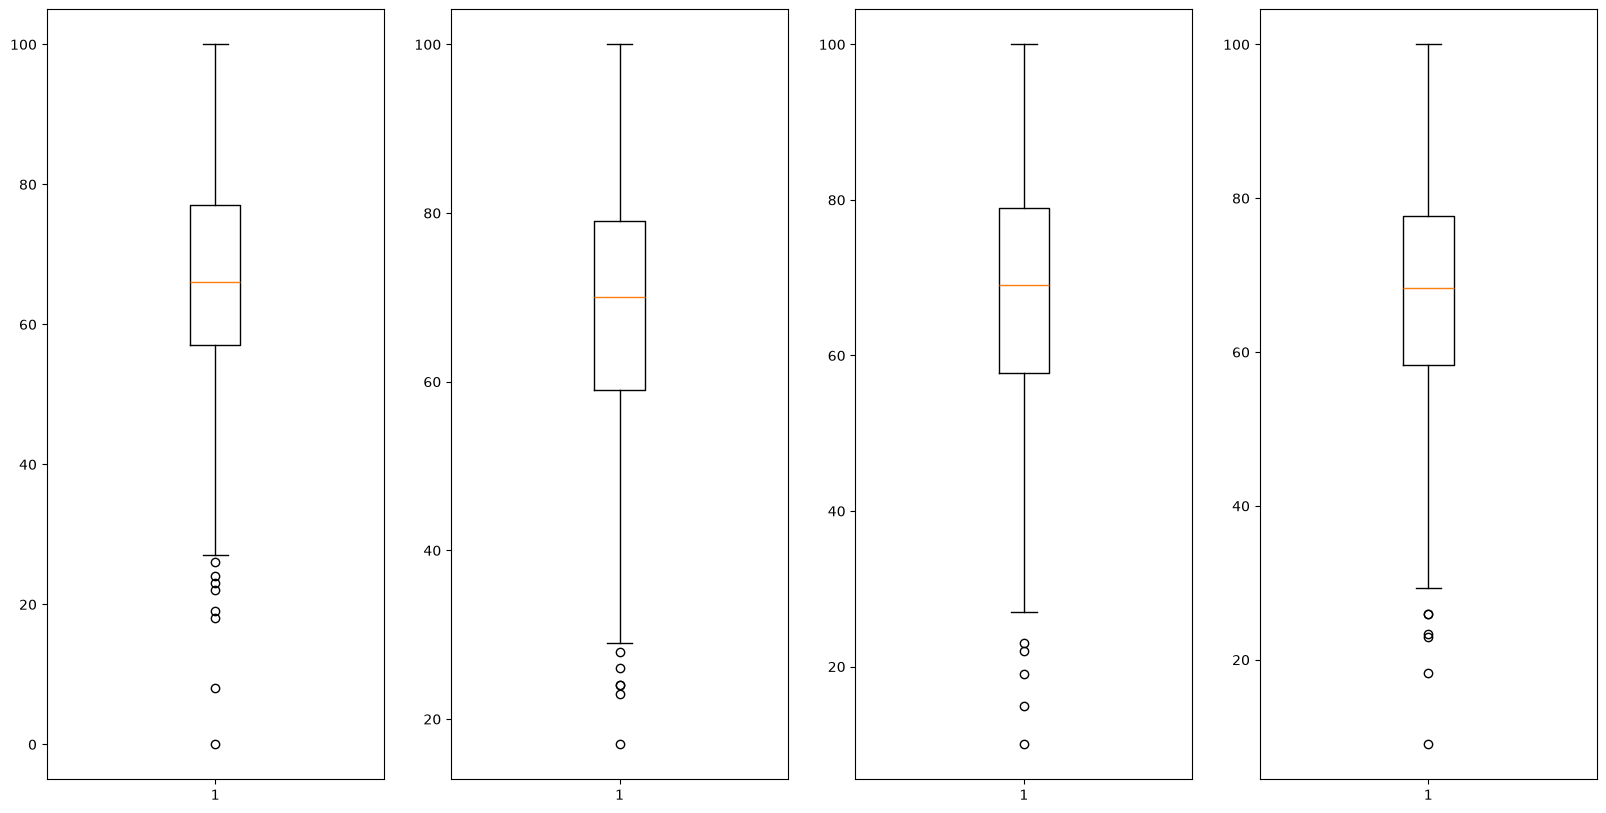

In [36]:
plt.subplots(1,4,figsize=(20,10))
plt.subplot(141)
plt.boxplot(x=df['math score'])
plt.subplot(142)
plt.boxplot(x=df['reading score'])
plt.subplot(143)
plt.boxplot(x=df['writing score'])
plt.subplot(144)
plt.boxplot(x=df['Average Score'])
plt.show()

Multivariate analysis using Pair plot


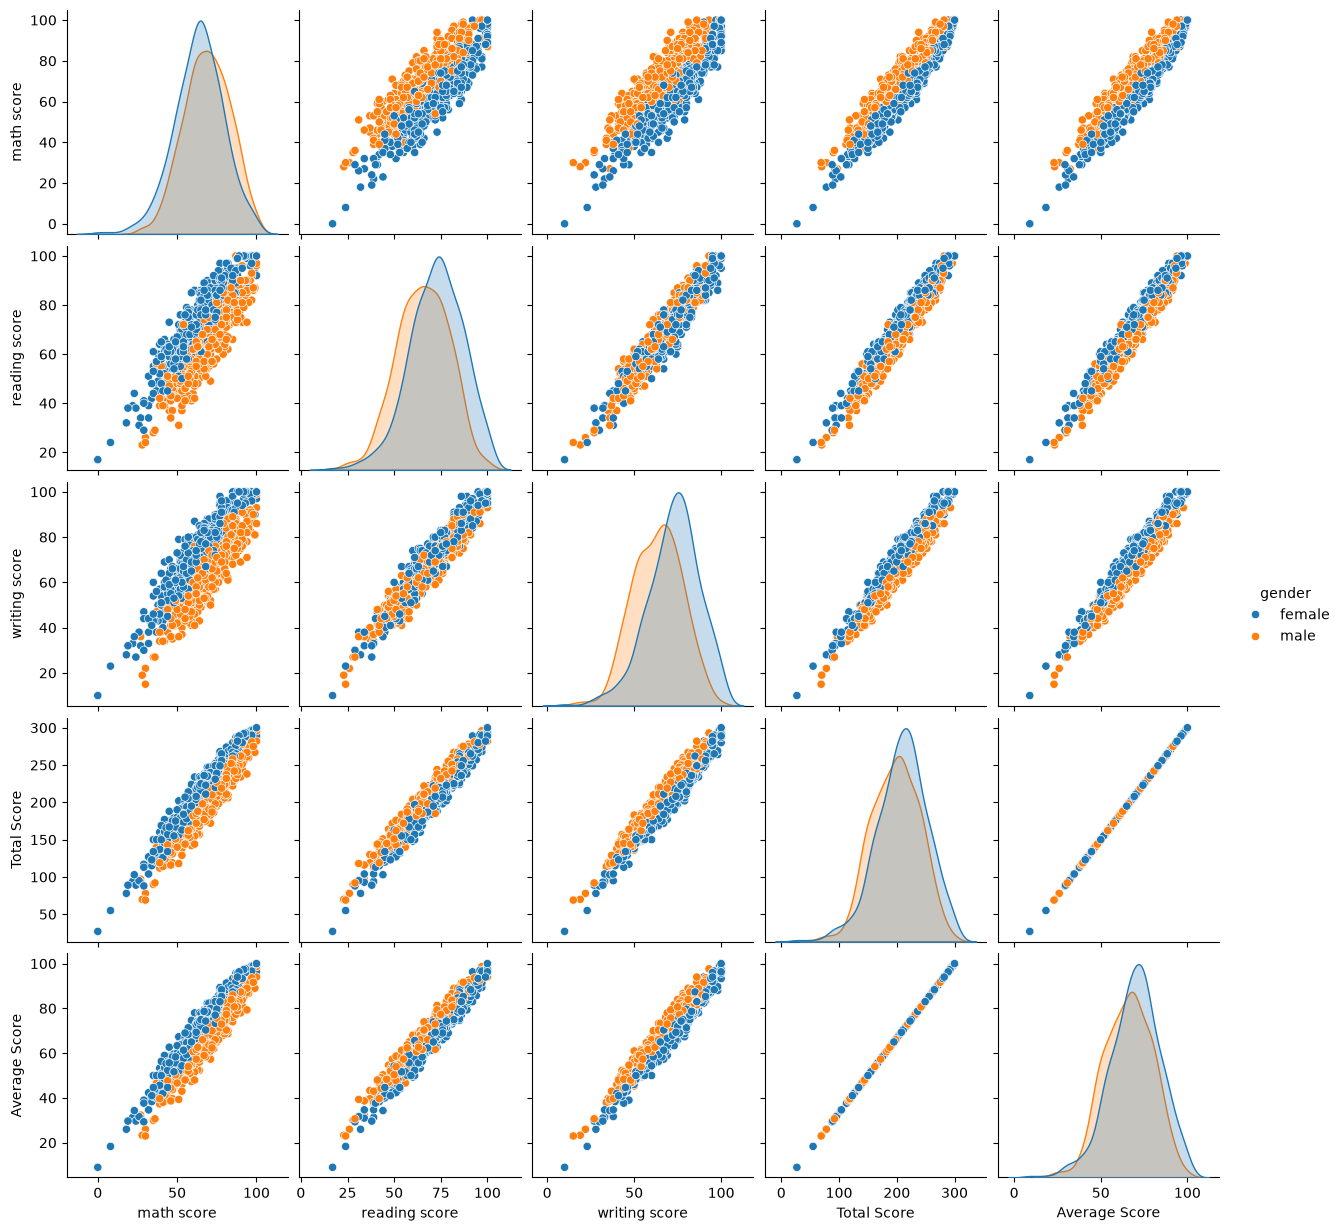

In [37]:
sns.pairplot(df,hue='gender')
plt.show()

Insights:
 1. By looking at all the scores all the scores are increasing linearly with each other. 